# Shoaling Trajectory Grid

Fast 5x7 trajectory-grid view for one 35-fish selection experiment. This notebook uses the slim selection notebook's `processingSettings.csv` as an experiment index and reads only the requested raw x/y trajectory columns.

## Settings

In [ ]:
from pathlib import Path
import glob
import hashlib
import json
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

repo_candidate = Path.cwd()
if repo_candidate.name == 'Analyses':
    repo_candidate = repo_candidate.parent
CODE_DIR = Path(os.environ.get('JLSOCIALBEHAVIOR_CODE_DIR', repo_candidate)).resolve()
os.chdir(CODE_DIR)

from functions.arena_use import calculate_arena_use_evenness

# Experiment index and animal metadata from the slim selection notebook. Edit these paths first for other datasets.
PROCESSING_SETTINGS_CSV = '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv'
META_FOLDER = '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/Carlos/Behavior/QTL/'
META_FILE = 'MetaData_QTL.xlsx'
OUTPUT_DIR = '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/'

# Experiment selection. Folder wins when set; otherwise SELECT_EXPERIMENT_INDEX is used.
SELECT_EXPERIMENT_FOLDER = None #just the folder name, you don't need the full path. Set to None to use SELECT_EXPERIMENT_INDEX instead.
SELECT_EXPERIMENT_INDEX = 10

# Time window controls. Default is first 2 hours; set USE_FULL_RECORDING=True to ignore TIME_WINDOW_MIN.
TIME_WINDOW_MIN = (60, 120) # (start, end) in minutes. The first 60 minutes should be ignored since they are the acclimation period.
USE_FULL_RECORDING = False
FRAME_STRIDE = 30 #  Number of frames to skip between sampled trajectory points used for the analysis. A value of 30 means we sample 1 frame per second. Set this variable to 1 to use all frames, but this will be computationally intensive and might not add much extra information.

# Data and output controls.
N_FISH = 35
FPS = 30
USE_TRAJECTORY_CACHE = True
SAVE_FIGURES = True
FIGURE_DPI = 180

# Sampled-frame occupancy heatmap controls for outlier screening.
# Each heatmap bin counts retained x/y positions in that bin.
# This makes the colors show where a fish was sampled; speed stays in labels.
ARENA_GRID_SIDE_BINS = 40 # Number of bins along each side of the arena grid. The grid is square, so this is the number of bins in both x and y.
# The helper keeps a bin only when its center lies inside the expected circular arena.
# Bins crossing the arena edge are included or excluded by their centers.
OCCUPANCY_HEATMAP_CMAP = 'viridis'
# Use one shared color scale across all 35 fish so bright panels are comparable.
# The 99th percentile avoids letting one extreme bin wash out the rest of the grid.
OCCUPANCY_HEATMAP_VMAX_PERCENTILE = 99
ARENA_EVENNESS_ZMAD_THRESHOLD = 1.5

os.makedirs(OUTPUT_DIR, exist_ok=True)
CACHE_DIR = os.path.join(OUTPUT_DIR, 'cache')
os.makedirs(CACHE_DIR, exist_ok=True)

print('Using repository:', CODE_DIR)
print('Using processing settings:', PROCESSING_SETTINGS_CSV)
print('Using animal metadata:', os.path.join(META_FOLDER, META_FILE))
print('Writing trajectory outputs to:', OUTPUT_DIR)

Using repository: C:\Users\crodri19\larschpostdoc_analyses\selection_shoaling\jlsocialbehavior
Using processing settings: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv
Using animal metadata: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/Carlos/Behavior/QTL/MetaData_QTL.xlsx
Writing trajectory outputs to: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/


## Helpers

In [2]:
# Keep only tiny helpers that are reused by more than one plotting cell.
# This function makes labels safe to use in filenames by replacing spaces,
# slashes, and other special characters with underscores.
def safe_filename(value):
    text = str(value).strip()
    return ''.join(char if char.isalnum() or char in '._-' else '_' for char in text)


## Select Experiment

In [3]:
# Load the processing table that lists all candidate experiments.
experiments = pd.read_csv(PROCESSING_SETTINGS_CSV, index_col=0)
if experiments.empty:
    raise ValueError('No experiments found in ' + PROCESSING_SETTINGS_CSV)

# Load animal metadata once. The trajectory-loading cell will use this table
# after it knows which animal IDs are present in the selected experiment.
meta_path = os.path.join(META_FOLDER, META_FILE)
if os.path.exists(meta_path):
    infoAn = pd.read_excel(meta_path, sheet_name='AllAn')
else:
    warnings.warn('Animal metadata file not found; subplot genotypes will be marked unknown: ' + meta_path)
    infoAn = pd.DataFrame(columns=['anNr', 'genotype'])

# Choose the experiment row. An explicit folder name is safer for repeated use;
# the numeric index is convenient for quick browsing.
if SELECT_EXPERIMENT_FOLDER is not None:
    matches = experiments[experiments['folder'].astype(str) == str(SELECT_EXPERIMENT_FOLDER)]
    if matches.empty:
        raise ValueError(f'SELECT_EXPERIMENT_FOLDER not found: {SELECT_EXPERIMENT_FOLDER}')
    selected_row = matches.iloc[0]
    selected_index = matches.index[0]
else:
    selected_index = experiments.index[SELECT_EXPERIMENT_INDEX]
    selected_row = experiments.loc[selected_index]

# Show a compact preview so the selected row can be checked before loading data.
preview_cols = [c for c in ['folder', 'date', 'setup', 'txtPath'] if c in experiments.columns]
display(experiments[preview_cols].reset_index().rename(columns={'index': 'processing_row'}).head(30))

print('Selected processing row:', selected_index)
print('Selected folder:', selected_row.get('folder', ''))
print('Raw trajectory file:', selected_row['txtPath'])


,processing_row,folder,date,setup,txtPath
0,0,20260511_q1_Sel1A_s1,11-05-2026,1,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
1,1,20260511_q2_Sel1A_s2,11-05-2026,2,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
2,2,20260512_q3_Sel3C_s1,12-05-2026,1,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
3,3,20260512_q4_Sel3C_s2,12-05-2026,2,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
4,4,20260518_q5_Sel3D_s1,18-05-2026,1,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
5,5,20260518_q6_Sel3D_s2,18-05-2026,2,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
6,6,20260519_q7_Sel1B_s1,19-05-2026,1,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
7,7,20260519_q8_Sel1B_s2,19-05-2026,2,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
8,8,20260626_q9_Sel1A_s2,26-06-2026,2,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...
9,9,20260731_q10_Sel3A_s1,31-07-2026,1,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...


Selected processing row: 10
Selected folder: 20260731_q11_Sel3A_s2
Raw trajectory file: \\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsch\default\D2c\07_Data\Carlos\Behavior\QTL\20260731_q11_Sel3A_s2\PositionTxt_allROI2026-07-31T10_52_17.csv


## Load Trajectory Window

In [4]:
# Convert the requested time window from minutes to raw video frames.
# When USE_FULL_RECORDING=True, n_rows stays None so pandas/numpy read to the end.
if USE_FULL_RECORDING or TIME_WINDOW_MIN is None:
    start_frame = 0
    n_rows = None
    window_label = 'full_recording'
else:
    start_min, stop_min = TIME_WINDOW_MIN
    if start_min < 0 or stop_min <= start_min:
        raise ValueError('TIME_WINDOW_MIN must be a (start, stop) tuple in minutes.')
    start_frame = int(round(start_min * 60 * FPS))
    stop_frame = int(round(stop_min * 60 * FPS))
    n_rows = stop_frame - start_frame
    window_label = f'{start_min:g}-{stop_min:g}_min'

# Build the same cache key as before: selected raw file, time window, stride,
# fish count, and raw-file modification time. Changing any of these creates a
# new cache file instead of silently reusing stale coordinates.
txt_path = str(selected_row['txtPath'])
experiment_label = selected_row.get('folder', Path(txt_path).stem)
try:
    raw_mtime = os.path.getmtime(txt_path)
except OSError:
    raw_mtime = None
cache_key = {
    'txt_path': txt_path,
    'txt_stem': Path(txt_path).stem,
    'experiment_label': str(experiment_label),
    'start_frame': start_frame,
    'n_rows': n_rows,
    'frame_stride': int(FRAME_STRIDE),
    'n_fish': int(N_FISH),
    'mtime': raw_mtime,
}
digest = hashlib.sha1(json.dumps(cache_key, sort_keys=True, default=str).encode('utf-8')).hexdigest()[:12]
cache_label = safe_filename(f'{experiment_label}_{Path(txt_path).stem}_{digest}')
trajectory_cache = os.path.join(CACHE_DIR, cache_label + '.npz')

if USE_TRAJECTORY_CACHE and os.path.exists(trajectory_cache):
    # Cached files already contain millimeter-centered coordinates and metadata.
    cached = np.load(trajectory_cache, allow_pickle=False)
    xy_mm = cached['xy_mm']
    animal_ids = cached['animal_ids']
    arena_radius_mm = float(cached['arena_radius_mm'])
    trajectory_meta = json.loads(str(cached['meta_json']))
    print('Loaded cached trajectory window:', trajectory_cache)
else:
    # Find the arena scaling information next to the raw trajectory file.
    # ROI files store arena radii in pixels; those radii convert x/y pixels to mm.
    arena_diameter_mm = float(selected_row.get('arenaDiameter_mm', 70))
    start_dir = os.path.dirname(txt_path)
    roi_patterns = [os.path.join(start_dir, 'ROIdef*')]
    roi_path = None
    for pattern in roi_patterns:
        matches = sorted(glob.glob(pattern))
        if matches:
            roi_path = matches[0]
            break

    if roi_path is not None:
        try:
            rois = np.atleast_2d(np.loadtxt(roi_path))
        except Exception:
            rois = np.atleast_2d(np.loadtxt(roi_path, delimiter=','))
        radii_px = rois[:N_FISH, -1].astype(float)
        px_per_mm = 2 * np.nanmean(radii_px) / arena_diameter_mm
        centers_px = radii_px + 2
        arena_radius_mm = arena_diameter_mm / 2
        scale_source = roi_path
    else:
        # Some processed folders use bgMed scale files instead of ROIdef files.
        scale_patterns = [
            os.path.join(start_dir, 'bgMed_scale*'),
            os.path.join(start_dir, '*bgMed.csv'),
        ]
        scale_path = None
        for pattern in scale_patterns:
            matches = sorted(glob.glob(pattern))
            if matches:
                scale_path = matches[0]
                break

        if scale_path is not None:
            rois = np.atleast_2d(np.loadtxt(scale_path, skiprows=1, delimiter=','))
            radius_col = 3 if rois.shape[1] > 3 else -1
            radii_px = rois[:N_FISH, radius_col].astype(float)
            px_per_mm = 2 * np.nanmean(radii_px) / arena_diameter_mm
            centers_px = radii_px + 2
            arena_radius_mm = arena_diameter_mm / 2
            scale_source = scale_path
        elif 'pxPmm' in selected_row and pd.notna(selected_row['pxPmm']):
            warnings.warn('No ROI file found; using pxPmm and leaving coordinates uncentered.')
            px_per_mm = float(selected_row['pxPmm'])
            centers_px = np.zeros(N_FISH)
            arena_radius_mm = arena_diameter_mm / 2
            scale_source = 'pxPmm column'
        else:
            raise FileNotFoundError('No ROI file or pxPmm value found for ' + txt_path)

    # Parse the local animal IDs from the processing row. If no explicit IDs are
    # present, use 0..N_FISH-1 so every subplot still has a stable label.
    animal_id_source = None
    if 'anIDAll' in selected_row and pd.notna(selected_row['anIDAll']):
        animal_id_source = selected_row['anIDAll']
    elif 'anNr' in selected_row and pd.notna(selected_row['anNr']):
        animal_id_source = selected_row['anNr']

    if animal_id_source is None:
        animal_ids = np.arange(N_FISH)
    else:
        animal_id_text = str(animal_id_source).strip()
        if not animal_id_text or animal_id_text.lower() == 'nan':
            animal_ids = np.arange(N_FISH)
        elif ':' in animal_id_text:
            start_id, stop_id = animal_id_text.split(':', 1)
            animal_ids = np.arange(int(start_id), int(stop_id) + 1)
        else:
            animal_ids = np.array(re.split(r'[\s,]+', animal_id_text), dtype=int)
        if len(animal_ids) < N_FISH:
            raise ValueError(f'Animal ID list has {len(animal_ids)} entries but N_FISH={N_FISH}.')
        animal_ids = animal_ids[:N_FISH]

    # Read only x/y columns for the selected fish. Each fish contributes three raw
    # columns; this notebook uses the first two as x and y and skips the third.
    xy_cols = [col for fish in range(N_FISH) for col in (fish * 3, fish * 3 + 1)]
    if txt_path[-3:].lower() == 'npy':
        raw = np.load(txt_path)
        stop = None if n_rows is None else start_frame + n_rows
        raw_xy = raw[start_frame:stop:FRAME_STRIDE, :N_FISH, :2].astype(float)
    else:
        first_line = pd.read_csv(txt_path, header=None, nrows=1, sep=':')
        first_value = str(first_line.values[0][0])
        first_char = first_value[0] if first_value else ''

        if first_char == '(':
            raise ValueError('Old Bonsai format is not supported by this fast 35-fish trajectory reader.')
        if first_char == 'X':
            skiprows = [0] + list(range(1, start_frame + 1)) if start_frame else [0]
        else:
            skiprows = range(start_frame) if start_frame else None

        raw_xy_table = pd.read_csv(
            txt_path,
            header=None,
            delim_whitespace=True,
            usecols=xy_cols,
            skiprows=skiprows,
            nrows=n_rows,
        ).to_numpy(dtype=float)
        raw_xy_table = raw_xy_table[::FRAME_STRIDE]
        raw_xy = raw_xy_table.reshape(raw_xy_table.shape[0], N_FISH, 2)

    # Center every fish's x/y coordinates on its arena and convert pixels to mm.
    xy_mm = (raw_xy - centers_px[np.newaxis, :, np.newaxis]) / px_per_mm
    trajectory_meta = {
        'folder': str(selected_row.get('folder', '')),
        'txt_path': txt_path,
        'txt_stem': Path(txt_path).stem,
        'window_label': window_label,
        'start_frame': start_frame,
        'n_rows_requested': n_rows,
        'frame_stride': int(FRAME_STRIDE),
        'fps': int(FPS),
        'px_per_mm': float(px_per_mm),
        'scale_source': str(scale_source),
        'cache_key': cache_key,
    }

    if USE_TRAJECTORY_CACHE:
        np.savez_compressed(
            trajectory_cache,
            xy_mm=xy_mm,
            animal_ids=np.asarray(animal_ids),
            arena_radius_mm=np.asarray(arena_radius_mm),
            meta_json=np.asarray(json.dumps(trajectory_meta, default=str, sort_keys=True)),
        )
        print('Cached trajectory window:', trajectory_cache)
    else:
        print('Trajectory cache disabled; parsed raw trajectory file.')

# Match plotted animal IDs to genotype labels from the metadata sheet.
if infoAn is None or infoAn.empty:
    animal_genotypes = np.array(['unknown'] * len(animal_ids), dtype=object)
else:
    missing_cols = {'anNr', 'genotype'} - set(infoAn.columns)
    if missing_cols:
        raise ValueError('Animal metadata is missing required columns: ' + ', '.join(sorted(missing_cols)))

    metadata = infoAn[['anNr', 'genotype']].copy()
    metadata['anNr'] = pd.to_numeric(metadata['anNr'], errors='coerce')
    metadata = metadata.dropna(subset=['anNr']).drop_duplicates('anNr', keep='last')
    genotype_by_animal = metadata.set_index('anNr')['genotype']

    genotype_labels = []
    for animal_id in animal_ids:
        animal_key = pd.to_numeric(pd.Series([animal_id]), errors='coerce').iloc[0]
        genotype = genotype_by_animal.get(animal_key, np.nan)
        if pd.isna(genotype) or str(genotype).strip() == '':
            genotype_labels.append('unknown')
        else:
            genotype_labels.append(str(genotype).strip())
    animal_genotypes = np.asarray(genotype_labels, dtype=object)

print('xy_mm shape:', xy_mm.shape)
print('animal IDs:', animal_ids)
print('animal genotypes:', animal_genotypes)
print('arena radius (mm):', arena_radius_mm)
print('scale source:', trajectory_meta.get('scale_source'))


Loaded cached trajectory window: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/cache\20260731_q11_Sel3A_s2_PositionTxt_allROI2026-07-31T10_52_17_fabd17ff8141.npz
xy_mm shape: (3600, 35, 2)
animal IDs: [351 352 353 354 355 356 357 358 359 360 361 362 363 364 365 366 367 368
 369 370 371 372 373 374 375 376 377 378 379 380 381 382 383 384 385]
animal genotypes: ['F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2'
 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2'
 'F2' 'F2' 'F2' 'F2' 'F2' 'F2' 'F2']
arena radius (mm): 35.0
scale source: \\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsch\default\D2c\07_Data\Carlos\Behavior\QTL\20260731_q11_Sel3A_s2\ROIdef2026-07-31T09_24_34.csv


# Arena use analysis

The arena-use helper divides the dish into a grid and converts each fish's sampled trajectory into a frame-count heatmap and a normalized probability distribution of the arena grid bins. Each retained x/y position contributes one count to its spatial bin.

The speed labels and outlier table still use frame-to-frame distance, and the table below is sorted by `movement_z_mad_abs`, so the strongest movement outliers appear first regardless of whether they moved much more or much less than the cohort median.

`movement_z_mad` is a robust MAD z-score for `distance_per_min`: `0.6745 * (fish_mm_per_min - cohort_median_mm_per_min) / MAD`. Positive values are more active than the median fish in this plotted window; negative values are less active. `movement_z_mad_abs` is the absolute value used only for ranking potential outliers.

In [ ]:
# Build arena-use arrays with the shared helper, then calculate movement metrics.
# The helper owns the fixed expected-arena grid, sampled-frame counts, probability
# distribution, coverage diagnostics, and normalized Shannon evenness.
n_fish = xy_mm.shape[1]
n_rows, n_cols = 5, 7
if n_fish != n_rows * n_cols:
    raise ValueError(f'Expected {n_rows * n_cols} fish for a 5x7 grid, got {n_fish}.')
if len(animal_genotypes) != n_fish:
    raise ValueError(f'Expected {n_fish} genotype labels, got {len(animal_genotypes)}.')

bins = ARENA_GRID_SIDE_BINS
cmap = OCCUPANCY_HEATMAP_CMAP
vmax_percentile = OCCUPANCY_HEATMAP_VMAX_PERCENTILE

sample_seconds = float(trajectory_meta.get('frame_stride', FRAME_STRIDE)) / float(trajectory_meta.get('fps', FPS))

arena_use = calculate_arena_use_evenness(
    xy_mm,
    arena_radius_mm=arena_radius_mm,
    bin_count=bins,
)
edges = arena_use.bin_edges
grid_x = arena_use.grid_x
grid_y = arena_use.grid_y
inside_arena = arena_use.arena_mask
heatmaps = arena_use.occupancy_frame_counts
arena_probability = arena_use.probability
extent = [edges[0], edges[-1], edges[0], edges[-1]]

metric_rows = []
for fish_idx in range(n_fish):
    xy = xy_mm[:, fish_idx, :]
    valid_positions = np.isfinite(xy).all(axis=1)

    # Consecutive sampled positions define one movement step for speed metrics.
    steps = xy[1:] - xy[:-1]
    step_midpoints = (xy[1:] + xy[:-1]) / 2
    step_distance = np.sqrt(np.sum(steps ** 2, axis=1))
    valid_steps = np.isfinite(step_midpoints).all(axis=1) & np.isfinite(step_distance)
    valid_steps &= step_distance > 0

    total_distance_mm = float(np.nansum(step_distance[valid_steps]))
    valid_duration_min = float(valid_steps.sum() * sample_seconds / 60)
    distance_per_min = total_distance_mm / valid_duration_min if valid_duration_min > 0 else np.nan
    mean_speed_mm_s = total_distance_mm / (valid_duration_min * 60) if valid_duration_min > 0 else np.nan
    arena_coverage_fraction = float(arena_use.coverage_fraction[fish_idx])

    metric_rows.append({
        'fish_idx': fish_idx,
        'animal_id': animal_ids[fish_idx],
        'genotype': str(animal_genotypes[fish_idx]).strip() or 'unknown',
        'valid_samples': int(valid_positions.sum()),
        'valid_intervals': int(valid_steps.sum()),
        'valid_duration_min': valid_duration_min,
        'total_distance_mm': total_distance_mm,
        'distance_per_min': distance_per_min,
        'mean_speed_mm_s': mean_speed_mm_s,
        'arena_coverage_fraction': arena_coverage_fraction,
    })

movement_metrics = pd.DataFrame(metric_rows)

# Robust z-score: compare every fish's mm/min movement rate to the cohort median.
# MAD is less distorted by one extreme fish than a standard deviation would be.
movement_values = pd.Series(movement_metrics['distance_per_min'], dtype='float64')
movement_median = movement_values.median(skipna=True)
movement_mad = (movement_values - movement_median).abs().median(skipna=True)
if pd.isna(movement_mad) or movement_mad == 0:
    movement_metrics['movement_z_mad'] = 0.0
else:
    movement_metrics['movement_z_mad'] = 0.6745 * (movement_values - movement_median) / movement_mad
movement_metrics['movement_z_mad_abs'] = movement_metrics['movement_z_mad'].abs()



## Per-Fish Arena-Use Evenness Calculation

The eveness metric uses the probability distribution returned by the arena-use helper. Every fish is scored against the same set of equal-area bins whose centers fall within the expected arena radius (`arenaDiameter_mm / 2`). This allows us to include bins on the edge of the dish while excluding bins outside of it. 

In [ ]:
# Attach the helper's per-fish arena-use metrics to the movement table, then
# screen evenness relative to all fish in this experiment and time window.
# The helper already owns grid construction, occupancy, probability, entropy,
# coverage, and the common expected-arena normalization denominator.
# arena_use.arena_bin_count counts bins whose centers fall inside the circle,
# even if this fish never visited it. Evenness divides Shannon entropy by
# log(arena_use.arena_bin_count), giving every fish the same denominator.
required_evenness_columns = {'fish_idx', 'animal_id', 'genotype'}
missing_evenness_columns = required_evenness_columns - set(movement_metrics.columns)
if missing_evenness_columns:
    raise ValueError('movement_metrics is missing columns: ' + ', '.join(sorted(missing_evenness_columns)))

required_evenness_vars = ['arena_use', 'arena_radius_mm']
missing_evenness_vars = [name for name in required_evenness_vars if name not in globals()]
if missing_evenness_vars:
    raise ValueError('Run the movement heatmap cell first; missing: ' + ', '.join(missing_evenness_vars))

# Compare a metric with the median across fish in this experiment/window.
# MAD = median(abs(value - median)); zMAD = 0.6745 * (value - median) / MAD.
# The factor gives a standard-deviation-like scale for normally distributed data.
# Missing entries are omitted from the reference and retain NaN scores. If MAD
# is zero or unavailable, nonmissing entries receive 0 (no outlier flag).
def _robust_z_mad(values):
    values = pd.Series(values, dtype='float64')
    median = values.median(skipna=True)
    mad = (values - median).abs().median(skipna=True)
    if pd.isna(mad) or mad == 0:
        return pd.Series(np.where(values.notna(), 0.0, np.nan), index=values.index, dtype='float64')
    return 0.6745 * (values - median) / mad

n_fish = len(arena_use.evenness)
if len(movement_metrics) != n_fish:
    raise ValueError('Arena-use results and movement metrics have different fish counts.')

arena_evenness = pd.DataFrame({
    'fish_idx': np.arange(n_fish),
    'reachable_bin_count': arena_use.arena_bin_count,
    'visited_reachable_bin_count': arena_use.visited_bin_count,
    'total_binned_frame_count': arena_use.total_binned_frame_count,
    'arena_evenness_shannon': arena_use.evenness,
    'arena_bias_index': arena_use.bias_index,
    'reachable_coverage_fraction': arena_use.coverage_fraction,
})

# Screen relative to ALL fish here, pooled across genotypes. This flag is a
# cohort-relative screening cutoff, not a p-value or fixed biological limit.
# Thresholds come from Settings. Comparisons with NaN return False, so an
# unscorable fish is not flagged by these comparisons; check its raw metric too.
arena_evenness['arena_evenness_z_mad'] = _robust_z_mad(arena_evenness['arena_evenness_shannon'])
arena_evenness['low_arena_evenness_flag'] = arena_evenness['arena_evenness_z_mad'] <= -ARENA_EVENNESS_ZMAD_THRESHOLD

# 7. Attach the results by fish_idx, which indexes both xy_mm and heatmaps.
# Remove earlier versions of these columns first so rerunning this cell replaces
# scores cleanly without creating duplicate merge columns or changing identities.
evenness_columns = [
    'reachable_bin_count',
    'visited_reachable_bin_count',
    'total_binned_frame_count',
    'arena_evenness_shannon',
    'arena_bias_index',
    'reachable_coverage_fraction',
    'arena_evenness_z_mad',
    'low_arena_evenness_flag',
]
movement_metrics = movement_metrics.drop(
    columns=[
        column for column in evenness_columns
        if column in movement_metrics.columns
    ],
    errors='ignore',
).merge(arena_evenness[['fish_idx'] + evenness_columns], on='fish_idx', how='left')

# Sort a display copy: low-evenness flags first, then lower evenness zMAD.
# This ranks fish for inspection; no fish are removed from movement_metrics.
arena_evenness_screen = movement_metrics.copy()
arena_evenness_screen = arena_evenness_screen.sort_values(
    ['low_arena_evenness_flag', 'arena_evenness_z_mad'],
    ascending=[False, True],
).reset_index(drop=True)

# SAVE_FIGURES also controls this CSV export. Save the full joined metrics table
# in its original order; the ranked display below uses arena_evenness_screen.
folder = trajectory_meta.get('folder') or trajectory_meta.get('txt_stem', '')
evenness_output_base = os.path.join(
    OUTPUT_DIR,
    safe_filename(f'occupancy_heatmap_grid_{folder}_{trajectory_meta.get("window_label", "window")}')
)
if SAVE_FIGURES:
    evenness_csv = evenness_output_base + '_arena_evenness.csv'
    movement_metrics.to_csv(evenness_csv, index=False)
    print('Wrote:', evenness_csv)

print('Expected arena radius (mm):', arena_radius_mm)
print('Expected-arena bin count:', arena_use.arena_bin_count)
print('Low arena-evenness flags:', int(arena_evenness['low_arena_evenness_flag'].sum()))

display_columns = [
    'fish_idx',
    'animal_id',
    'genotype',
    'arena_evenness_shannon',
    'arena_bias_index',
    'arena_evenness_z_mad',
    'low_arena_evenness_flag',
    'reachable_coverage_fraction',
    'reachable_bin_count',
    'visited_reachable_bin_count',
]
display(arena_evenness_screen[display_columns])


Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/movement_heatmap_grid_20260731_q11_Sel3A_s2_60-120_min_arena_evenness.csv
Expected arena radius (mm): 35.0
Expected-arena bin count: 1264
Low arena-evenness flags: 5


,fish_idx,animal_id,genotype,arena_evenness_shannon,arena_bias_index,arena_evenness_z_mad,low_arena_evenness_flag,reachable_coverage_fraction,reachable_bin_count,visited_reachable_bin_count
0,6,357,F2,0.776207,0.223793,-4.126619,True,0.397152,1264,502
1,16,367,F2,0.815389,0.184611,-2.815856,True,0.556171,1264,703
2,29,380,F2,0.828496,0.171504,-2.377402,True,0.522943,1264,661
3,34,385,F2,0.844113,0.155887,-1.854956,True,0.493671,1264,624
4,0,351,F2,0.852872,0.147128,-1.561928,True,0.496835,1264,628
5,2,353,F2,0.858554,0.141446,-1.371871,False,0.659019,1264,833
6,13,364,F2,0.865933,0.134067,-1.124995,False,0.520570,1264,658
7,20,371,F2,0.866283,0.133717,-1.113300,False,0.496835,1264,628
8,4,355,F2,0.874729,0.125271,-0.830756,False,0.520570,1264,658
9,12,363,F2,0.876948,0.123052,-0.756518,False,0.591772,1264,748


## Plot heatmap of arena use

Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/movement_heatmap_grid_20260731_q11_Sel3A_s2_60-120_min.png
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/movement_heatmap_grid_20260731_q11_Sel3A_s2_60-120_min.pdf
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/movement_heatmap_grid_20260731_q11_Sel3A_s2_60-120_min_metrics.csv


,fish_idx,animal_id,genotype,valid_samples,valid_intervals,valid_duration_min,total_distance_mm,distance_per_min,mean_speed_mm_s,arena_coverage_fraction,movement_z_mad,movement_z_mad_abs,reachable_bin_count,visited_reachable_bin_count,total_binned_frame_count,arena_evenness_shannon,arena_bias_index,reachable_coverage_fraction,arena_evenness_z_mad,low_arena_evenness_flag
0,31,382,F2,3600,3596,59.933333,21679.621882,361.728952,6.028816,0.722310,3.544067,3.544067,1264,913,3600,0.932225,0.067775,0.722310,1.092670,False
1,6,357,F2,3600,3097,51.616667,6656.230632,128.955066,2.149251,0.397152,-2.402124,2.402124,1264,502,3600,0.776207,0.223793,0.397152,-4.126619,True
2,24,375,F2,3600,3587,59.783333,18474.830915,309.029789,5.150496,0.727848,2.197871,2.197871,1264,920,3600,0.926934,0.073066,0.727848,0.915682,False
3,34,385,F2,3600,3267,54.450000,7936.284163,145.753612,2.429227,0.493671,-1.973006,1.973006,1264,624,3600,0.844113,0.155887,0.493671,-1.854956,True
4,19,370,F2,3600,3534,58.900000,17378.501904,295.050966,4.917516,0.592563,1.840783,1.840783,1264,749,3600,0.894755,0.105245,0.592563,-0.160826,False
5,0,351,F2,3600,3487,58.116667,9290.222088,159.854696,2.664245,0.496835,-1.612795,1.612795,1264,628,3600,0.852872,0.147128,0.496835,-1.561928,True
6,23,374,F2,3600,3579,59.650000,16212.484546,271.793538,4.529892,0.700949,1.246674,1.246674,1264,886,3600,0.927190,0.072810,0.700949,0.924256,False
7,14,365,F2,3600,3506,58.433333,10185.267065,174.305768,2.905096,0.629747,-1.243644,1.243644,1264,796,3600,0.899562,0.100438,0.629747,0.000000,False
8,10,361,F2,3600,3555,59.250000,15988.007862,269.839795,4.497330,0.655854,1.196766,1.196766,1264,829,3600,0.912636,0.087364,0.655854,0.437382,False
9,16,367,F2,3600,2959,49.316667,8748.956631,177.403649,2.956727,0.556171,-1.164508,1.164508,1264,703,3600,0.815389,0.184611,0.556171,-2.815856,True


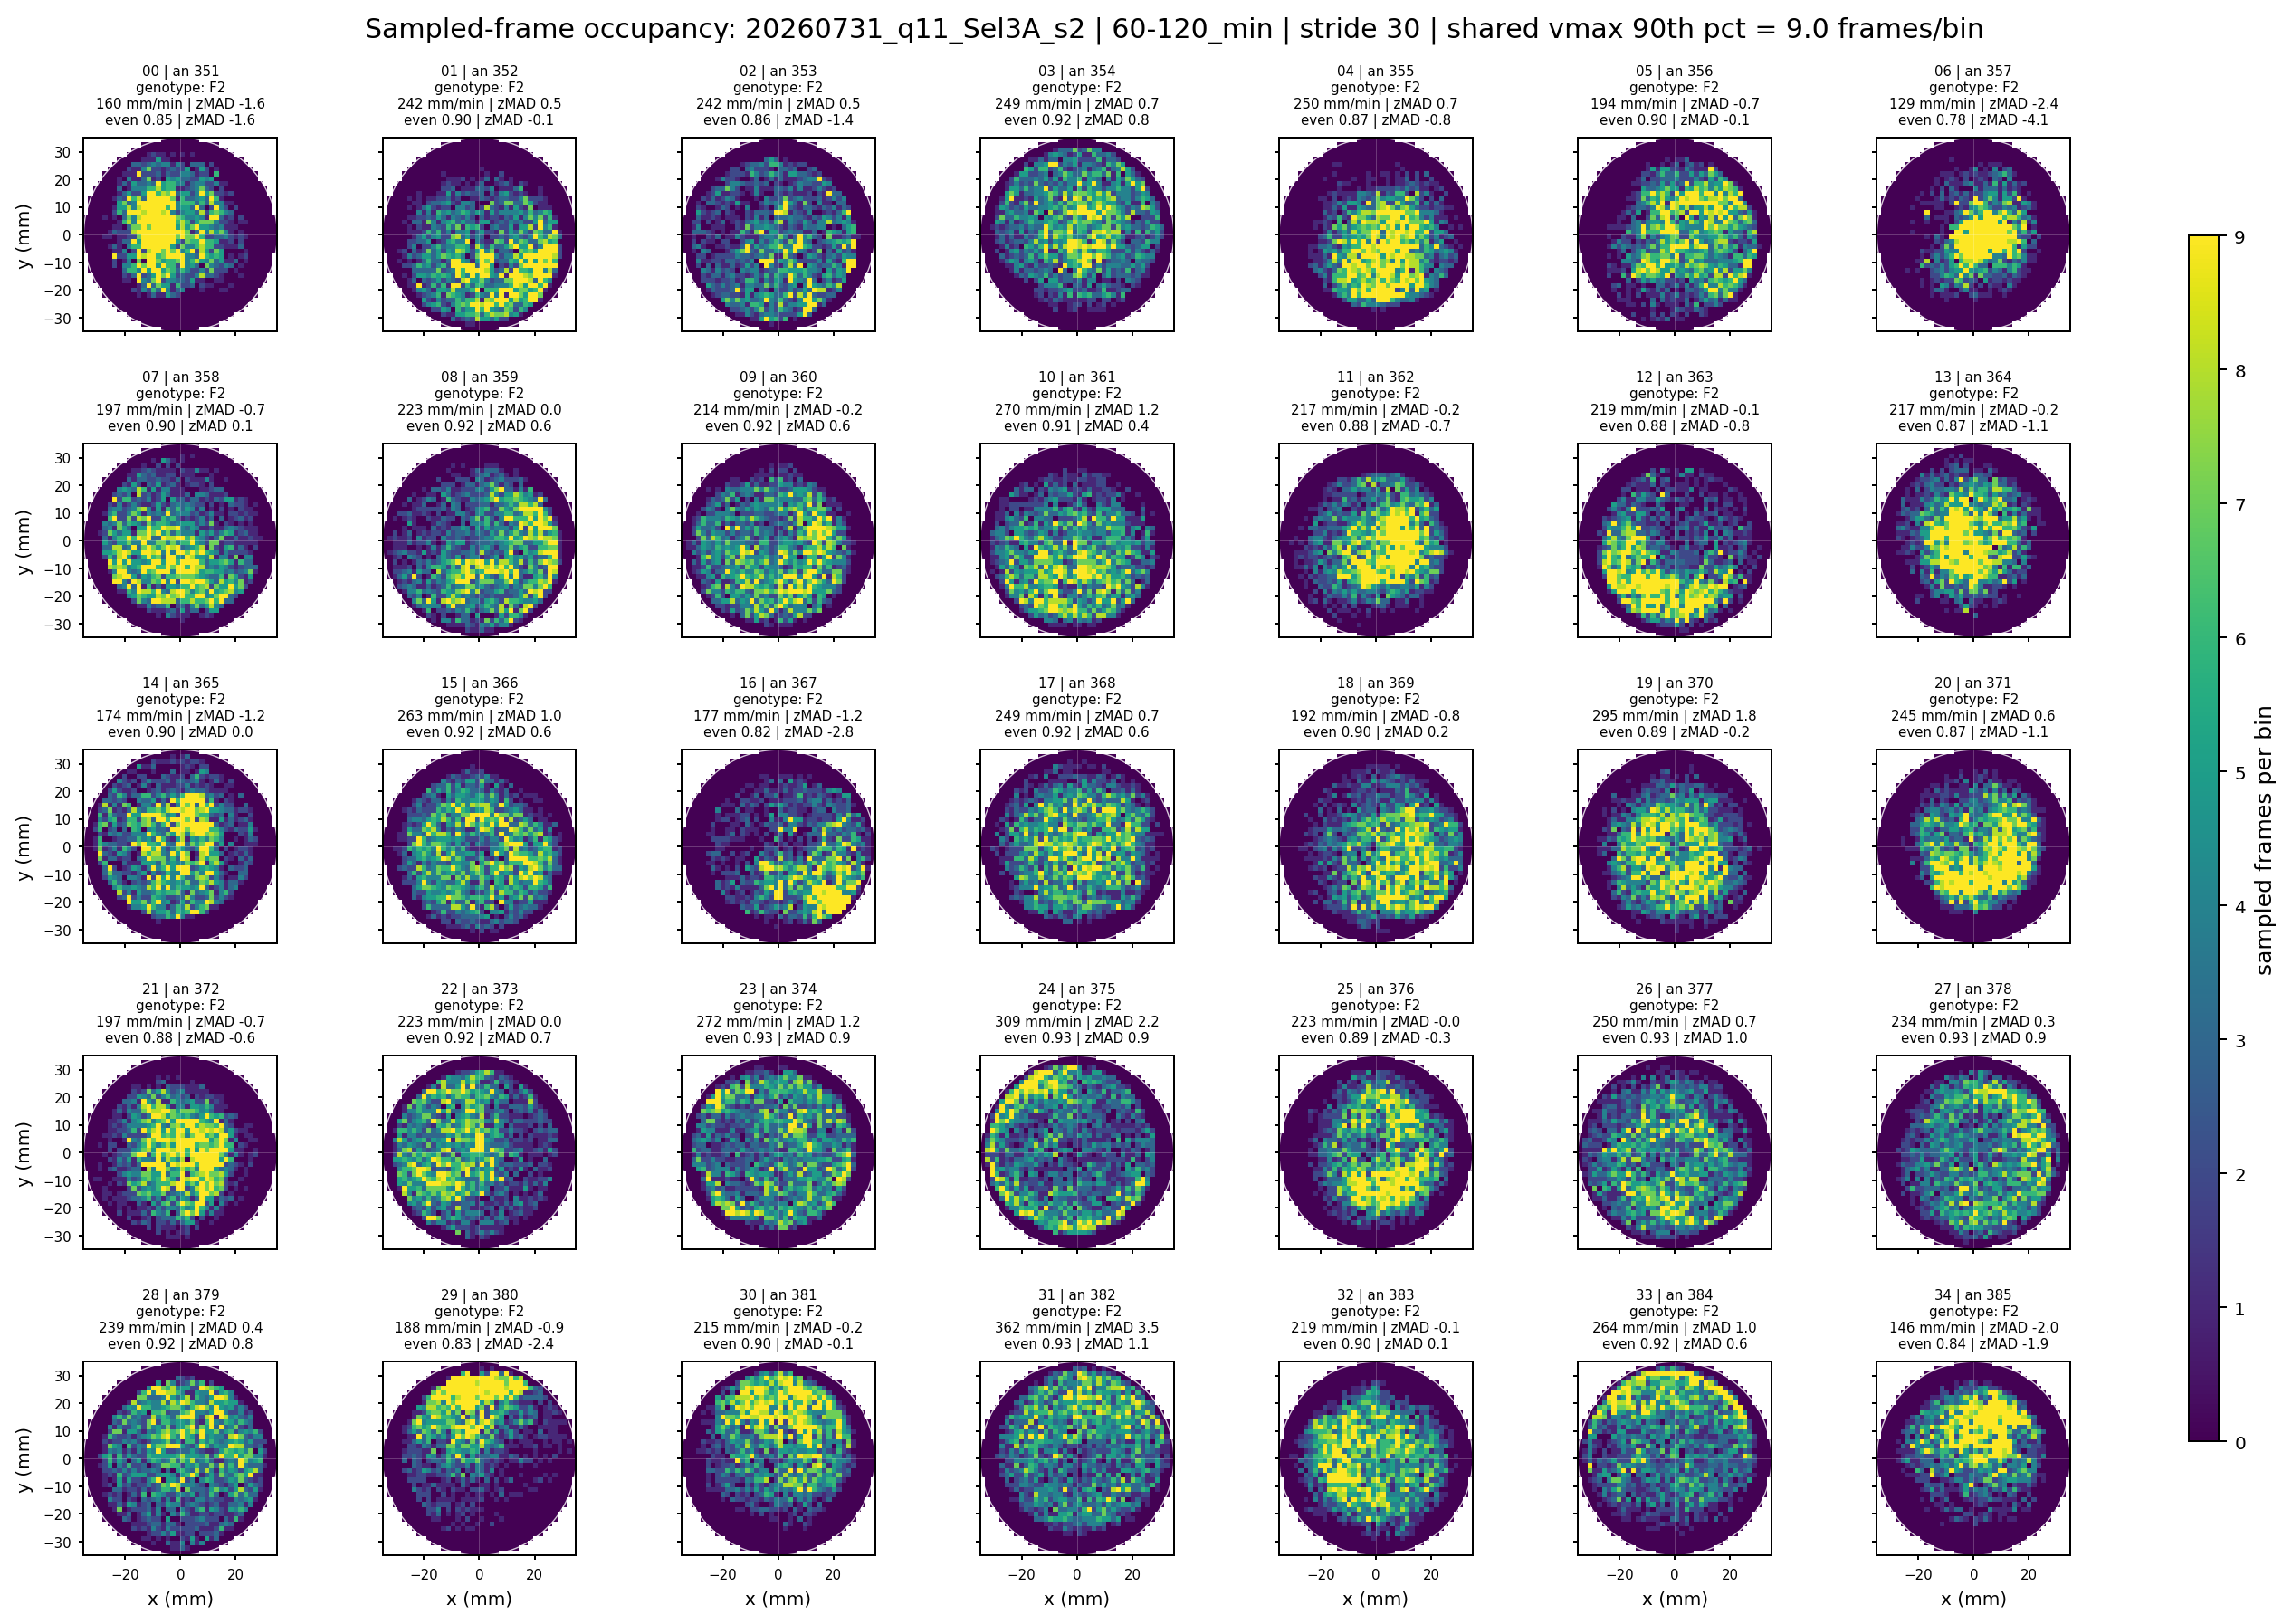

In [ ]:
# Plot the 5x7 heatmap grid after arena-use evenness has been added to movement_metrics.
required_heatmap_label_columns = {
    'fish_idx',
    'animal_id',
    'genotype',
    'distance_per_min',
    'movement_z_mad',
    'arena_evenness_shannon',
    'arena_evenness_z_mad',
}
missing_heatmap_label_columns = required_heatmap_label_columns - set(movement_metrics.columns)
if missing_heatmap_label_columns:
    raise ValueError('movement_metrics is missing columns: ' + ', '.join(sorted(missing_heatmap_label_columns)))

# Pick one color scale for all 35 heatmaps, using only positive in-arena bins.
# This makes bright panels comparable across fish without one extreme bin washing
# out the rest of the experiment.
positive_values = heatmaps[np.isfinite(heatmaps) & (heatmaps > 0)]
vmax = float(np.nanpercentile(positive_values, vmax_percentile)) if positive_values.size else 1.0
if not np.isfinite(vmax) or vmax <= 0:
    vmax = 1.0

heatmap_fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10), sharex=True, sharey=True, dpi=FIGURE_DPI)
theta = np.linspace(0, 2 * np.pi, 181)
circle_x = arena_radius_mm * np.cos(theta)
circle_y = arena_radius_mm * np.sin(theta)
im = None

for fish_idx, ax in enumerate(axes.ravel()):
    im = ax.imshow(
        np.ma.masked_invalid(heatmaps[fish_idx]),
        origin='lower',
        extent=extent,
        cmap=cmap,
        vmin=0,
        vmax=vmax,
        interpolation='nearest',
        rasterized=True,
    )
    ax.plot(circle_x, circle_y, color='white', lw=0.55, alpha=0.8)
    ax.axhline(0, color='white', lw=0.25, alpha=0.35, zorder=2)
    ax.axvline(0, color='white', lw=0.25, alpha=0.35, zorder=2)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect('equal', adjustable='box')

    # The title repeats the most useful screening numbers: movement rate and
    # robust deviation from the cohort median.
    row = movement_metrics.iloc[fish_idx]
    ax.set_title(
        f'{fish_idx:02d} | an {row["animal_id"]}\n'
        f'genotype: {row["genotype"]}\n'
        f'{row["distance_per_min"]:.0f} mm/min | zMAD {row["movement_z_mad"]:.1f}\n'
        f'even {row["arena_evenness_shannon"]:.2f} | zMAD {row["arena_evenness_z_mad"]:.1f}',
        fontsize=6.0,
    )
    ax.tick_params(labelsize=6, length=2)

for ax in axes[-1, :]:
    ax.set_xlabel('x (mm)', fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel('y (mm)', fontsize=8)

folder = trajectory_meta.get('folder') or trajectory_meta.get('txt_stem', '')
heatmap_fig.suptitle(
    f'Sampled-frame occupancy: {folder} | {trajectory_meta.get("window_label", "window")} | '
    f'stride {trajectory_meta.get("frame_stride")} | shared vmax {vmax_percentile:g}th pct = {vmax:.1f} frames/bin',
    fontsize=12,
    y=0.995,
)
heatmap_fig.subplots_adjust(left=0.04, right=0.88, bottom=0.05, top=0.92, wspace=0.15, hspace=0.58)

# Put the shared colorbar in a fixed outer axis so it does not steal space from
# the rightmost subplots.
cbar_ax = heatmap_fig.add_axes([0.915, 0.12, 0.012, 0.74])
cbar = heatmap_fig.colorbar(im, cax=cbar_ax, label='sampled frames per bin')
cbar.ax.tick_params(labelsize=8)

output_base = os.path.join(
    OUTPUT_DIR,
    safe_filename(f'occupancy_heatmap_grid_{folder}_{trajectory_meta.get("window_label", "window")}')
)
if SAVE_FIGURES:
    heatmap_fig.savefig(output_base + '.png', dpi=FIGURE_DPI, bbox_inches='tight')
    heatmap_fig.savefig(output_base + '.pdf', bbox_inches='tight')
    movement_metrics.to_csv(output_base + '_metrics.csv', index=False)
    print('Wrote:', output_base + '.png')
    print('Wrote:', output_base + '.pdf')
    print('Wrote:', output_base + '_metrics.csv')

# Sort by absolute robust deviation so both very high movement and very low
# movement fish rise to the top for manual screening.
# Column meanings:
# - fish_idx: local subplot index in the 5x7 grid.
# - animal_id and genotype: metadata labels for the plotted fish.
# - valid_samples: finite x/y positions available for sampled-frame heatmap bins.
# - valid_intervals: finite nonzero steps used for distance and speed metrics.
# - valid_duration_min: valid_intervals converted to elapsed minutes.
# - total_distance_mm: summed valid step distance in the window.
# - distance_per_min and mean_speed_mm_s: movement rate in mm/min and mm/s.
# - arena_coverage_fraction: fraction of in-arena heatmap bins with any sampled occupancy.
# - movement_z_mad: robust cohort-centered z-score of distance_per_min.
# - movement_z_mad_abs: absolute zMAD used for this outlier ranking.
movement_outliers = movement_metrics.sort_values('movement_z_mad_abs', ascending=False).reset_index(drop=True)
display(movement_outliers)
plt.show()


## Plot fish speed distribution

Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_speed_distribution_20260731_q11_Sel3A_s2_60-120_min.png
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_speed_distribution_20260731_q11_Sel3A_s2_60-120_min.pdf
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_speed_distribution_20260731_q11_Sel3A_s2_60-120_min_speed.csv


,fish_idx,animal_id,genotype,valid_samples,valid_intervals,valid_duration_min,total_distance_mm,distance_per_min,mean_speed_mm_s,arena_coverage_fraction,movement_z_mad,movement_z_mad_abs,reachable_bin_count,visited_reachable_bin_count,total_binned_frame_count,arena_evenness_shannon,arena_bias_index,reachable_coverage_fraction,arena_evenness_z_mad,low_arena_evenness_flag
0,31,382,F2,3600,3596,59.933333,21679.621882,361.728952,6.028816,0.722310,3.544067,3.544067,1264,913,3600,0.932225,0.067775,0.722310,1.092670,False
1,24,375,F2,3600,3587,59.783333,18474.830915,309.029789,5.150496,0.727848,2.197871,2.197871,1264,920,3600,0.926934,0.073066,0.727848,0.915682,False
2,19,370,F2,3600,3534,58.900000,17378.501904,295.050966,4.917516,0.592563,1.840783,1.840783,1264,749,3600,0.894755,0.105245,0.592563,-0.160826,False
3,23,374,F2,3600,3579,59.650000,16212.484546,271.793538,4.529892,0.700949,1.246674,1.246674,1264,886,3600,0.927190,0.072810,0.700949,0.924256,False
4,10,361,F2,3600,3555,59.250000,15988.007862,269.839795,4.497330,0.655854,1.196766,1.196766,1264,829,3600,0.912636,0.087364,0.655854,0.437382,False
5,33,384,F2,3600,3560,59.333333,15649.804136,263.760744,4.396012,0.704905,1.041477,1.041477,1264,891,3600,0.918048,0.081952,0.704905,0.618429,False
6,15,366,F2,3600,3595,59.916667,15743.490908,262.756455,4.379274,0.666139,1.015822,1.015822,1264,842,3600,0.918606,0.081394,0.666139,0.637090,False
7,4,355,F2,3600,3583,59.716667,14954.294454,250.420783,4.173680,0.520570,0.700709,0.700709,1264,658,3600,0.874729,0.125271,0.520570,-0.830756,False
8,26,377,F2,3600,3587,59.783333,14919.239658,249.555166,4.159253,0.734177,0.678596,0.678596,1264,928,3600,0.930724,0.069276,0.734177,1.042473,False
9,3,354,F2,3600,3581,59.683333,14843.768159,248.708766,4.145146,0.695411,0.656975,0.656975,1264,879,3600,0.924939,0.075061,0.695411,0.848938,False


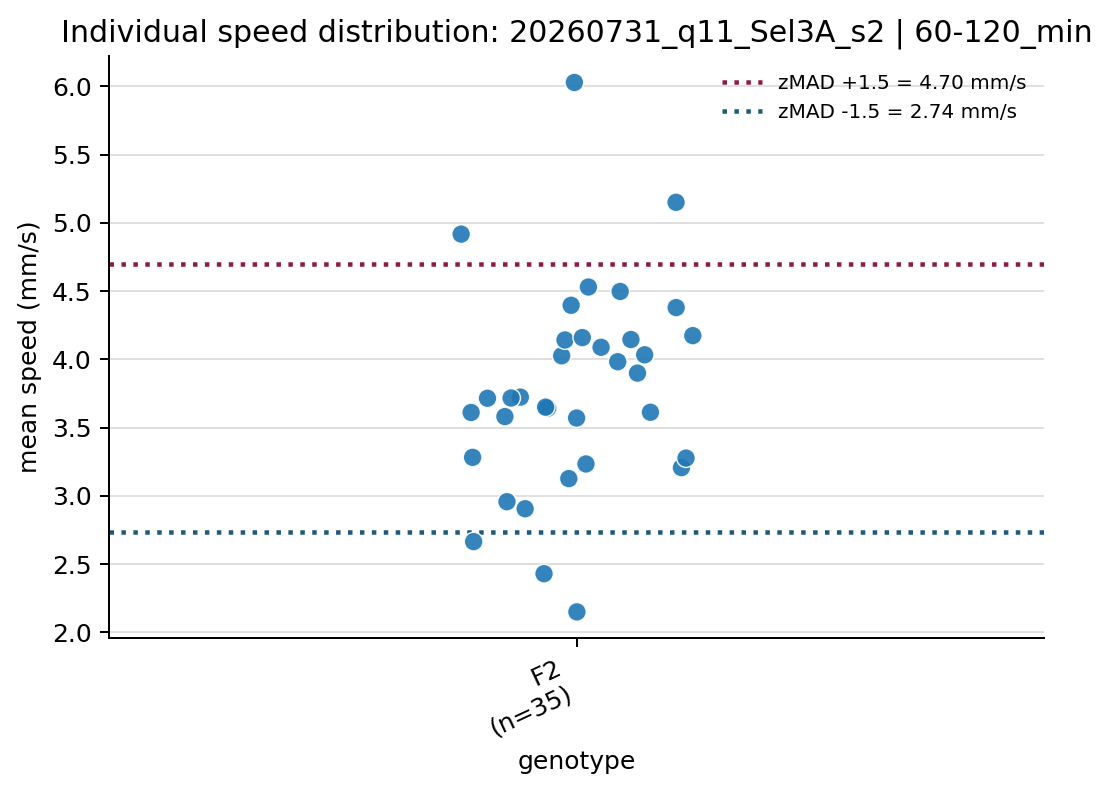

In [8]:
# Plot each fish's mean speed from the movement_metrics table generated above.
# The required columns check gives a clear error if the heatmap cell has not been
# run or if the metrics table structure changes later.
required_speed_columns = {'fish_idx', 'animal_id', 'genotype', 'distance_per_min', 'mean_speed_mm_s'}
missing_speed_columns = required_speed_columns - set(movement_metrics.columns)
if missing_speed_columns:
    raise ValueError('movement_metrics is missing columns: ' + ', '.join(sorted(missing_speed_columns)))

# Clean genotype labels before grouping so blank labels appear as a visible
# 'unknown' group instead of being silently dropped or merged with whitespace.
individual_speed = movement_metrics.copy()
individual_speed['genotype'] = individual_speed['genotype'].astype(str).str.strip().replace('', 'unknown')
individual_speed = individual_speed[np.isfinite(individual_speed['mean_speed_mm_s'])].copy()
genotype_order = sorted(individual_speed['genotype'].unique())
genotype_counts = individual_speed.groupby('genotype').size().reindex(genotype_order)
palette_name = 'tab10' if len(genotype_order) <= 10 else 'tab20'
genotype_colors = dict(zip(genotype_order, sns.color_palette(palette_name, n_colors=len(genotype_order))))

# Jitter separates fish with the same genotype so individual points remain visible.
# The fixed random seed makes the displayed plot stable across reruns.
np.random.seed(7)
fig_width = max(6, 1.2 * len(genotype_order) + 2)
fig, ax = plt.subplots(figsize=(fig_width, 4.5), dpi=FIGURE_DPI)

sns.stripplot(
    data=individual_speed,
    x='genotype',
    y='mean_speed_mm_s',
    hue='genotype',
    order=genotype_order,
    hue_order=genotype_order,
    palette=genotype_colors,
    jitter=0.13,
    size=7.5,
    edgecolor='white',
    linewidth=0.6,
    alpha=0.9,
    legend=False,
    ax=ax,
    zorder=3,
)

# Draw the mean-speed values corresponding to movement zMAD = +/-3.
# zMAD is defined on distance_per_min above, then converted here to mm/s.
speed_zmad_threshold = 1.5
movement_values_for_speed = pd.Series(individual_speed['distance_per_min'], dtype='float64')
movement_median_for_speed = movement_values_for_speed.median(skipna=True)
movement_mad_for_speed = (movement_values_for_speed - movement_median_for_speed).abs().median(skipna=True)
if not pd.isna(movement_mad_for_speed) and movement_mad_for_speed != 0:
    zmad_delta = speed_zmad_threshold * movement_mad_for_speed / 0.6745
    zmad_speed_lines = [
        (f'zMAD +{speed_zmad_threshold:g}', (movement_median_for_speed + zmad_delta) / 60, '#8B1E3F'),
        (f'zMAD -{speed_zmad_threshold:g}', (movement_median_for_speed - zmad_delta) / 60, '#1F5A7A'),
    ]
    for zmad_label, speed_threshold, line_color in zmad_speed_lines:
        if np.isfinite(speed_threshold):
            ax.axhline(
                speed_threshold,
                color=line_color,
                linestyle=':',
                linewidth=1.8,
                label=f'{zmad_label} = {speed_threshold:.2f} mm/s',
                zorder=2,
            )

ax.set_xticks(range(len(genotype_order)))
ax.set_xticklabels([f'{genotype}\n(n={genotype_counts[genotype]})' for genotype in genotype_order], rotation=25, ha='right')
ax.set_ylabel('mean speed (mm/s)')
ax.set_xlabel('genotype')
ax.set_title(
    f'Individual speed distribution: {trajectory_meta.get("folder") or trajectory_meta.get("txt_stem", "")}'
    f' | {trajectory_meta.get("window_label", "window")}'
)
ax.grid(axis='y', color='0.88', linewidth=0.8)
sns.despine(ax=ax)
ax.legend(frameon=False, loc='best', fontsize=8)
fig.tight_layout()

if SAVE_FIGURES:
    folder = trajectory_meta.get('folder') or trajectory_meta.get('txt_stem', '')
    output_base = os.path.join(
        OUTPUT_DIR,
        safe_filename(f'individual_speed_distribution_{folder}_{trajectory_meta.get("window_label", "window")}')
    )
    fig.savefig(output_base + '.png', dpi=FIGURE_DPI, bbox_inches='tight')
    fig.savefig(output_base + '.pdf', bbox_inches='tight')
    individual_speed.to_csv(output_base + '_speed.csv', index=False)
    print('Wrote:', output_base + '.png')
    print('Wrote:', output_base + '.pdf')
    print('Wrote:', output_base + '_speed.csv')

display(individual_speed.sort_values('mean_speed_mm_s', ascending=False).reset_index(drop=True))
plt.show()


## Plot Individual Arena-Use Evenness

This point plot mirrors the speed distribution plot and shows expected-arena evenness across genotypes. Dotted lines mark the same robust zMAD thresholds used for screening.

Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_arena_evenness_distribution_20260731_q11_Sel3A_s2_60-120_min.png
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_arena_evenness_distribution_20260731_q11_Sel3A_s2_60-120_min.pdf
Wrote: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use//temp/shoaling_selection/ShoalQTL_temp_output/trajectory_grids/individual_arena_evenness_distribution_20260731_q11_Sel3A_s2_60-120_min_arena_evenness_distribution.csv


,fish_idx,animal_id,genotype,valid_samples,valid_intervals,valid_duration_min,total_distance_mm,distance_per_min,mean_speed_mm_s,arena_coverage_fraction,movement_z_mad,movement_z_mad_abs,reachable_bin_count,visited_reachable_bin_count,total_binned_frame_count,arena_evenness_shannon,arena_bias_index,reachable_coverage_fraction,arena_evenness_z_mad,low_arena_evenness_flag
0,6,357,F2,3600,3097,51.616667,6656.230632,128.955066,2.149251,0.397152,-2.402124,2.402124,1264,502,3600,0.776207,0.223793,0.397152,-4.126619,True
1,16,367,F2,3600,2959,49.316667,8748.956631,177.403649,2.956727,0.556171,-1.164508,1.164508,1264,703,3600,0.815389,0.184611,0.556171,-2.815856,True
2,29,380,F2,3600,3345,55.750000,10456.422057,187.559140,3.125986,0.522943,-0.905087,0.905087,1264,661,3600,0.828496,0.171504,0.522943,-2.377402,True
3,34,385,F2,3600,3267,54.450000,7936.284163,145.753612,2.429227,0.493671,-1.973006,1.973006,1264,624,3600,0.844113,0.155887,0.493671,-1.854956,True
4,0,351,F2,3600,3487,58.116667,9290.222088,159.854696,2.664245,0.496835,-1.612795,1.612795,1264,628,3600,0.852872,0.147128,0.496835,-1.561928,True
5,2,353,F2,3600,3088,51.466667,12431.803344,241.550583,4.025843,0.659019,0.474120,0.474120,1264,833,3600,0.858554,0.141446,0.659019,-1.371871,False
6,13,364,F2,3600,3487,58.116667,12589.751176,216.628928,3.610482,0.520570,-0.162502,0.162502,1264,658,3600,0.865933,0.134067,0.520570,-1.124995,False
7,20,371,F2,3600,3578,59.633333,14627.416663,245.289268,4.088154,0.496835,0.569624,0.569624,1264,628,3600,0.866283,0.133717,0.496835,-1.113300,False
8,4,355,F2,3600,3583,59.716667,14954.294454,250.420783,4.173680,0.520570,0.700709,0.700709,1264,658,3600,0.874729,0.125271,0.520570,-0.830756,False
9,12,363,F2,3600,3423,57.050000,12466.446156,218.517899,3.641965,0.591772,-0.114248,0.114248,1264,748,3600,0.876948,0.123052,0.591772,-0.756518,False


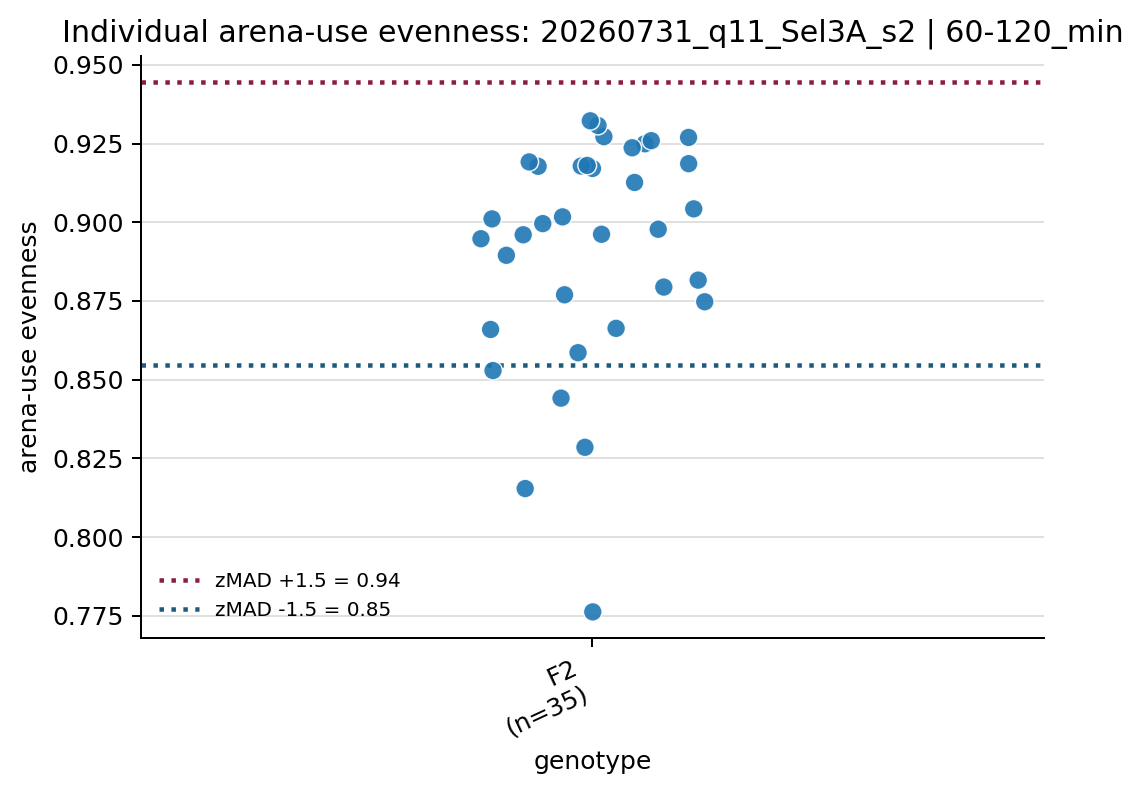

In [9]:
# Plot each fish's arena-use evenness from the movement_metrics table generated above.
required_evenness_plot_columns = {
    'fish_idx',
    'animal_id',
    'genotype',
    'arena_evenness_shannon',
    'arena_evenness_z_mad',
}
missing_evenness_plot_columns = required_evenness_plot_columns - set(movement_metrics.columns)
if missing_evenness_plot_columns:
    raise ValueError('movement_metrics is missing columns: ' + ', '.join(sorted(missing_evenness_plot_columns)))

individual_evenness = movement_metrics.copy()
individual_evenness['genotype'] = individual_evenness['genotype'].astype(str).str.strip().replace('', 'unknown')
individual_evenness = individual_evenness[np.isfinite(individual_evenness['arena_evenness_shannon'])].copy()
genotype_order = sorted(individual_evenness['genotype'].unique())
genotype_counts = individual_evenness.groupby('genotype').size().reindex(genotype_order)
palette_name = 'tab10' if len(genotype_order) <= 10 else 'tab20'
genotype_colors = dict(zip(genotype_order, sns.color_palette(palette_name, n_colors=len(genotype_order))))

np.random.seed(7)
fig_width = max(6, 1.2 * len(genotype_order) + 2)
fig, ax = plt.subplots(figsize=(fig_width, 4.5), dpi=FIGURE_DPI)

sns.stripplot(
    data=individual_evenness,
    x='genotype',
    y='arena_evenness_shannon',
    hue='genotype',
    order=genotype_order,
    hue_order=genotype_order,
    palette=genotype_colors,
    jitter=0.13,
    size=7.5,
    edgecolor='white',
    linewidth=0.6,
    alpha=0.9,
    legend=False,
    ax=ax,
    zorder=3,
)

evenness_values_for_plot = pd.Series(individual_evenness['arena_evenness_shannon'], dtype='float64')
evenness_median_for_plot = evenness_values_for_plot.median(skipna=True)
evenness_mad_for_plot = (evenness_values_for_plot - evenness_median_for_plot).abs().median(skipna=True)
if not pd.isna(evenness_mad_for_plot) and evenness_mad_for_plot != 0:
    zmad_delta = ARENA_EVENNESS_ZMAD_THRESHOLD * evenness_mad_for_plot / 0.6745
    zmad_evenness_lines = [
        (f'zMAD +{ARENA_EVENNESS_ZMAD_THRESHOLD:g}', evenness_median_for_plot + zmad_delta, '#8B1E3F'),
        (f'zMAD -{ARENA_EVENNESS_ZMAD_THRESHOLD:g}', evenness_median_for_plot - zmad_delta, '#1F5A7A'),
    ]
    for zmad_label, evenness_threshold, line_color in zmad_evenness_lines:
        if np.isfinite(evenness_threshold):
            ax.axhline(
                evenness_threshold,
                color=line_color,
                linestyle=':',
                linewidth=1.8,
                label=f'{zmad_label} = {evenness_threshold:.2f}',
                zorder=2,
            )

ax.set_xticks(range(len(genotype_order)))
ax.set_xticklabels([f'{genotype}\n(n={genotype_counts[genotype]})' for genotype in genotype_order], rotation=25, ha='right')
ax.set_ylabel('arena-use evenness')
ax.set_xlabel('genotype')
ax.set_title(
    f'Individual arena-use evenness: {trajectory_meta.get("folder") or trajectory_meta.get("txt_stem", "")}'
    f' | {trajectory_meta.get("window_label", "window")}'
)
#ax.set_ylim(0.8, 0.9)
ax.grid(axis='y', color='0.88', linewidth=0.8)
sns.despine(ax=ax)
ax.legend(frameon=False, loc='best', fontsize=8)
fig.tight_layout()

if SAVE_FIGURES:
    folder = trajectory_meta.get('folder') or trajectory_meta.get('txt_stem', '')
    output_base = os.path.join(
        OUTPUT_DIR,
        safe_filename(f'individual_arena_evenness_distribution_{folder}_{trajectory_meta.get("window_label", "window")}')
    )
    fig.savefig(output_base + '.png', dpi=FIGURE_DPI, bbox_inches='tight')
    fig.savefig(output_base + '.pdf', dpi=FIGURE_DPI, bbox_inches='tight')
    individual_evenness.to_csv(output_base + '_arena_evenness_distribution.csv', index=False)
    print('Wrote:', output_base + '.png')
    print('Wrote:', output_base + '.pdf')
    print('Wrote:', output_base + '_arena_evenness_distribution.csv')

display(individual_evenness.sort_values('arena_evenness_shannon', ascending=True).reset_index(drop=True))
plt.show()
